# Swiggy Sales Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Import Data

In [2]:
df = pd.read_excel(r'C:\Users\S-300V5A\Desktop\Data Analytics Skills\DA Project_Python\swiggy_data.xlsx')
df.head()

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
0,Karnataka,Bengaluru,2025-06-29,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0
1,Karnataka,Bengaluru,2025-04-03,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25
2,Karnataka,Bengaluru,2025-01-15,Srinidhi Sagar Deluxe,Kengeri,Recommended,Chow Chow Bath,117.0,4.7,48
3,Karnataka,Bengaluru,2025-04-17,Srinidhi Sagar Deluxe,Kengeri,Recommended,Kesari Bath,65.0,4.6,65
4,Karnataka,Bengaluru,2025-03-13,Srinidhi Sagar Deluxe,Kengeri,Recommended,Mix Raitha,130.0,4.0,0


# Metadata

In [3]:
#number of rows
df.shape[0]

197430

In [4]:
#number of columns
df.shape[1]

10

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197430 entries, 0 to 197429
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   State            197430 non-null  object        
 1   City             197430 non-null  object        
 2   Order Date       197430 non-null  datetime64[ns]
 3   Restaurant Name  197430 non-null  object        
 4   Location         197430 non-null  object        
 5   Category         197430 non-null  object        
 6   Dish Name        197430 non-null  object        
 7   Price (INR)      197430 non-null  float64       
 8   Rating           197430 non-null  float64       
 9   Rating Count     197430 non-null  int64         
dtypes: datetime64[ns](1), float64(2), int64(1), object(6)
memory usage: 15.1+ MB


In [6]:
df.dtypes

State                      object
City                       object
Order Date         datetime64[ns]
Restaurant Name            object
Location                   object
Category                   object
Dish Name                  object
Price (INR)               float64
Rating                    float64
Rating Count                int64
dtype: object

In [7]:
df.describe()

,Order Date,Price (INR),Rating,Rating Count
count,197430,197430.000000,197430.000000,197430.000000
mean,2025-05-01 19:41:20.996808960,268.512920,4.341582,28.321805
min,2025-01-01 00:00:00,0.950000,1.500000,0.000000
25%,2025-03-01 00:00:00,139.000000,4.300000,0.000000
50%,2025-05-02 00:00:00,229.000000,4.400000,2.000000
75%,2025-07-01 00:00:00,329.000000,4.500000,15.000000
max,2025-08-31 00:00:00,8000.000000,5.000000,999.000000
std,NaN,219.338363,0.422585,87.542593


# KPI's

# Total Sales

In [8]:

total_sales = round(df['Price (INR)'].sum(),2)

print("Total sales:",total_sales)


Total sales: 53012505.77


# Average Rating

In [9]:
average_rating = round(df['Rating'].mean(),2)
print("Average rating:",average_rating)#Total Sales

Average rating: 4.34


# Average Order Value

In [10]:
average_order_value = round(df['Price (INR)'].mean(),2)
print("Average Order Value:",average_order_value)


Average Order Value: 268.51


# Rating Count

In [11]:
rating_count = round(df['Rating Count'].sum(),2)
print("Rating Count:", rating_count)

Rating Count: 5591574


# Total Orders

In [12]:
print("Total Orders:", len(df))

Total Orders: 197430


# Monthly Sales Trend

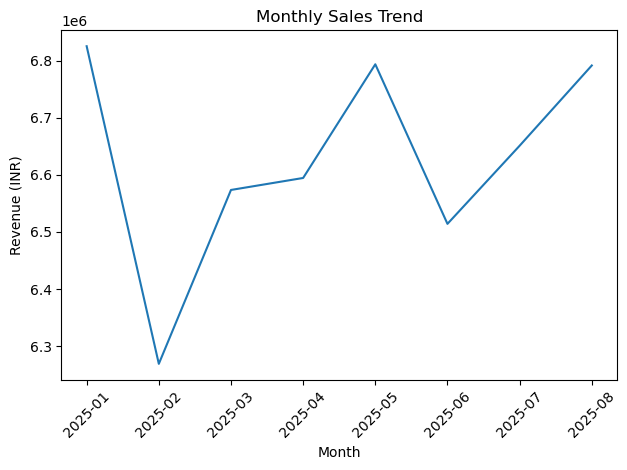

In [13]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['YearMonth'] = df['Order Date'].dt.to_period("M").astype(str)
monthly_revenue = df.groupby("YearMonth")["Price (INR)"].sum().reset_index()

plt.figure()
plt.plot(monthly_revenue["YearMonth"], monthly_revenue["Price (INR)"])
plt.xticks(rotation=45)
plt.xlabel('Month')
plt.ylabel('Revenue (INR)')
plt.title('Monthly Sales Trend')
plt.tight_layout()
plt.show()

# Daily Sales Trend

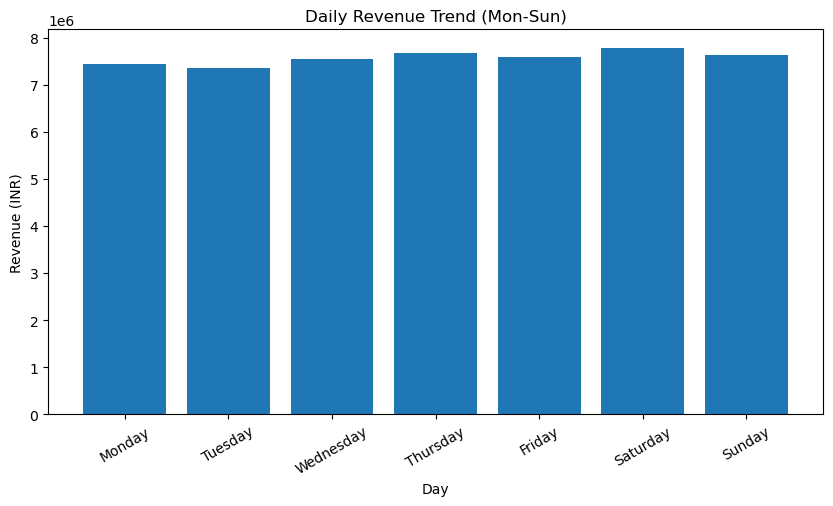

In [18]:
df['DayName'] = pd.to_datetime(df["Order Date"]).dt.day_name()

daily_revenue = (
    df.groupby("DayName")["Price (INR)"]
    .sum()
    .reindex(["Monday","Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
)

plt.figure(figsize=(10,5))
plt.bar(daily_revenue.index, daily_revenue.values)
plt.title("Daily Revenue Trend (Mon-Sun)")
plt.xlabel("Day")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=30)

plt.show()

# Total Sales by Food Type

In [20]:
non_veg_keywords = [
    "chicken", "egg", "fish", "mutton",
    "prawn", "biryani", "kebab", "kabab",
    "non-veg", "non veg"
]

df['Food Category'] = np.where(
    df["Dish Name"].str.lower().str.contains("|".join(non_veg_keywords), na=False),
    "Non-Veg",
    "Veg"
)

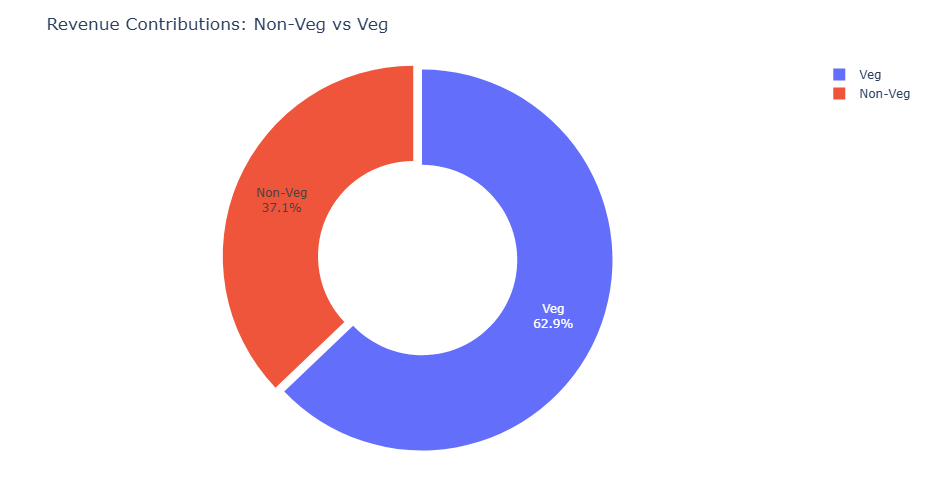

In [27]:
food_revenue = df.groupby('Food Category')['Price (INR)'].sum().reset_index()

fig = px.pie(
    food_revenue,
    values="Price (INR)",
    names="Food Category",
    hole=0.5,
    title="Revenue Contributions: Non-Veg vs Veg",
)

fig.update_traces(
    textinfo="percent+label",
    pull=(0.05,0)
)

fig.update_layout(
    height=500,
    margin=dict(t=60, b=40, l=40, r=40)
)

fig.show()

# Total Sales by Map

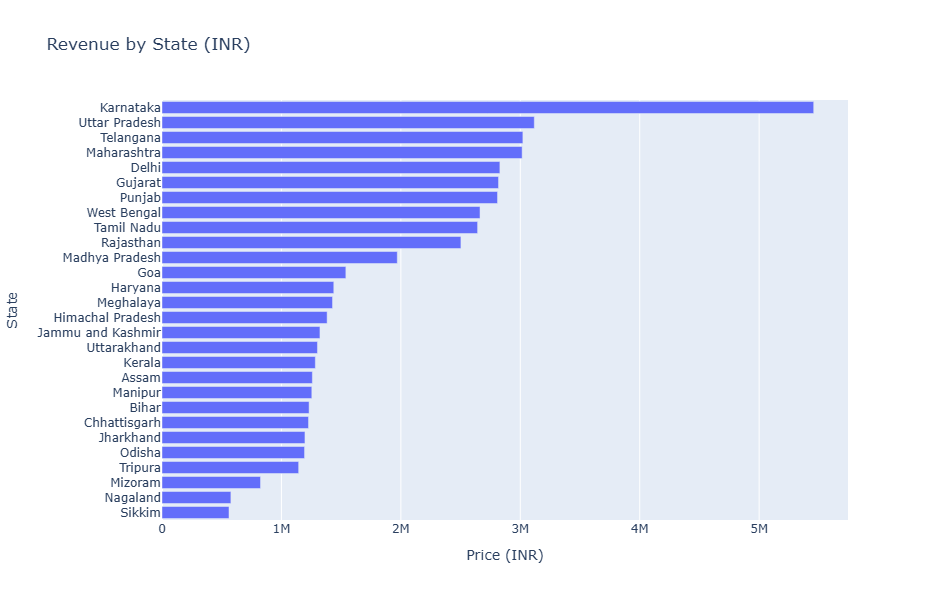

In [30]:
fig = px.bar(
    df.groupby("State", as_index=False)['Price (INR)'].sum()
        .sort_values("Price (INR)", ascending=False),
    x="Price (INR)",
    y="State",
    orientation="h",
    title="Revenue by State (INR)"       
)
fig.update_layout(height=600, yaxis=dict(autorange="reversed"))
fig.show()

# Quarterly Performance Summary

In [36]:
df["Order_Date"] = pd.to_datetime(df["Order Date"])
df["Quarter"] = df["Order_Date"].dt.to_period("Q").astype(str)
quarterly_summary = (
    df.groupby("Quarter", as_index=False)
    .agg(
        Total_Sales = ("Price (INR)", "sum"),
        Avg_Rating = ("Rating", "mean"),
        Total_Orders = ("Order_Date", "count")
    )
    .sort_values("Quarter")
)
quarterly_summary

,Quarter,Total_Sales,Avg_Rating,Total_Orders
0,2025Q1,19667821.77,4.342643,73096
1,2025Q2,19902256.59,4.340011,74163
2,2025Q3,13442427.41,4.342359,50171


# Top 5 Cities by Sales

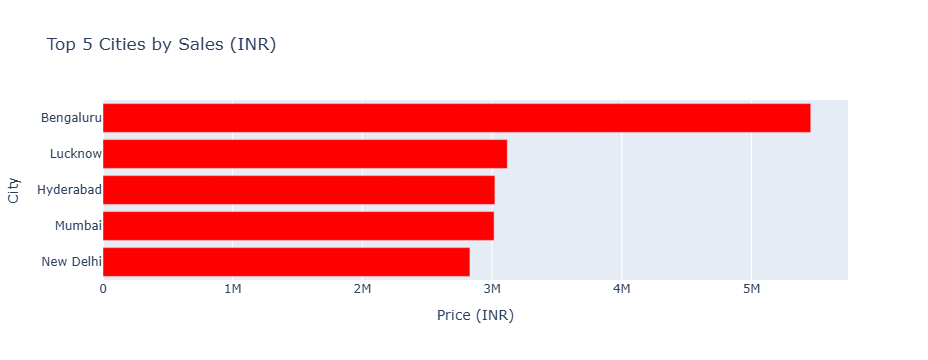

In [38]:
top_5_cities = (
    df.groupby('City')['Price (INR)']
        .sum()
        .nlargest(5)
        .sort_values()
    .reset_index()
)

fig = px.bar(
    top_5_cities,
    x='Price (INR)',
    y='City',
    orientation="h",
    title="Top 5 Cities by Sales (INR)",
    color_discrete_sequence=["red"]
)

fig.show()

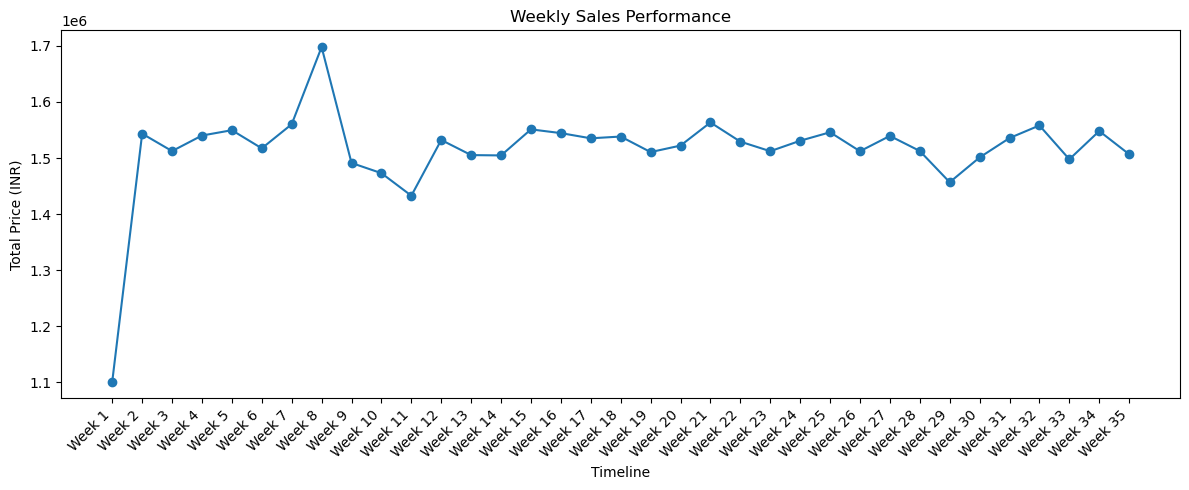

In [45]:

df["Week"] = df["Order_Date"].dt.to_period("W").astype(str)


weekly_data = df.groupby("Week")["Price (INR)"].sum().reset_index()


weekly_data["Week_Label"] = [f"Week {i+1}" for i in range(len(weekly_data))]


plt.figure(figsize=(12, 5))
plt.plot(weekly_data["Week_Label"], weekly_data["Price (INR)"], marker="o", color="tab:blue")


plt.xticks(rotation=45, ha="right")
plt.ylabel("Total Price (INR)")
plt.xlabel("Timeline")
plt.title("Weekly Sales Performance")

plt.tight_layout()
plt.show()



In [44]:
df

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count,YearMonth,DayName,Food Category,Quarter,Order_Date,Week
0,Karnataka,Bengaluru,2025-06-29,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0,2025-06,Sunday,Veg,2025Q2,2025-06-29,2025-06-23/2025-06-29
1,Karnataka,Bengaluru,2025-04-03,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25,2025-04,Thursday,Veg,2025Q2,2025-04-03,2025-03-31/2025-04-06
2,Karnataka,Bengaluru,2025-01-15,Srinidhi Sagar Deluxe,Kengeri,Recommended,Chow Chow Bath,117.0,4.7,48,2025-01,Wednesday,Veg,2025Q1,2025-01-15,2025-01-13/2025-01-19
3,Karnataka,Bengaluru,2025-04-17,Srinidhi Sagar Deluxe,Kengeri,Recommended,Kesari Bath,65.0,4.6,65,2025-04,Thursday,Veg,2025Q2,2025-04-17,2025-04-14/2025-04-20
4,Karnataka,Bengaluru,2025-03-13,Srinidhi Sagar Deluxe,Kengeri,Recommended,Mix Raitha,130.0,4.0,0,2025-03,Thursday,Veg,2025Q1,2025-03-13,2025-03-10/2025-03-16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
197425,Sikkim,Gangtok,2025-01-25,Mama's Kitchen,Gangtok,Momos,Soya cheese chilli momo ...,112.0,4.4,0,2025-01,Saturday,Veg,2025Q1,2025-01-25,2025-01-20/2025-01-26
197426,Sikkim,Gangtok,2025-07-02,Mama's Kitchen,Gangtok,Momos,Kurkure momo fried ...,140.0,4.4,0,2025-07,Wednesday,Veg,2025Q3,2025-07-02,2025-06-30/2025-07-06
197427,Sikkim,Gangtok,2025-03-25,Mama's Kitchen,Gangtok,Momos,Chilli cheese momo,126.0,4.4,0,2025-03,Tuesday,Veg,2025Q1,2025-03-25,2025-03-24/2025-03-30
197428,Sikkim,Gangtok,2025-03-26,Mama's Kitchen,Gangtok,Momos,Veg Momos (8 Pc),85.0,4.4,0,2025-03,Wednesday,Veg,2025Q1,2025-03-26,2025-03-24/2025-03-30
